# Tutorial：Gene imputation on mouse cortex seqFISH+ data with mouse primary visual cortex (VISp) Smart-seq data as a reference

## Outline

1. Import packages
2. Load data
3. Batch effect correction
4. Construct graphs and extract features
5. Microenvironment representations learning for scRNA-seq data
6. Gene imputation (using "micro-aware" mode)
7. Caculate mean PCC of test genes
8. Marker genes visualization

## 1. Import packages

We need to specify the working directory in R.

In [1]:
import scanpy as sc
import os
from pathlib import Path
import cellback as cb
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch
import random
os.environ['R_HOME'] = '/home/liujixin/anaconda3/envs/cellback_env/lib/R/'
os.environ['R_USER'] = '/home/liujixin/anaconda3/envs/cellback_env/lib/R/library'

## 2. Load data

We perform 10-fold cross-validation on the dataset (ST data: seqFISH+, scRNA data: Smart-seq, Tissue: mouse cortex). A total of 1,000 highly variable genes are split into training and testing sets at a 9:1 ratio, and the 10th fold is shown here as an example.

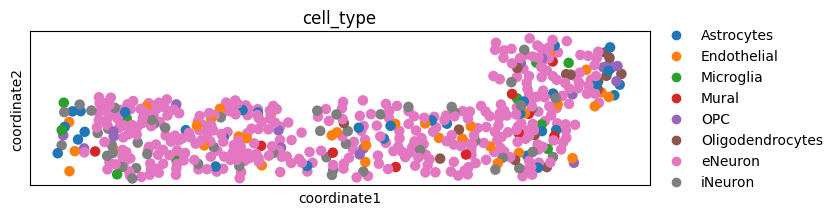

In [2]:
#the 10-th fold of 10-fold cross-validation
data_dir = Path("../CellBack/data/dataset4/")
slide = sc.read_h5ad(data_dir / "dataset4_st.h5ad")
singlecell = sc.read_h5ad(data_dir / "dataset4_sc.h5ad")

plt.rcParams["figure.figsize"] = (8, 2)
sc.pl.embedding(slide, basis="coordinate", color='cell_type')

list = np.load(data_dir / "test_list.npy")
test_gene = list[9]
test_genes = [str(g) for g in test_gene]
slide = slide[:, ~np.isin(slide.var_names, test_genes)]

sc.pp.normalize_total(slide, target_sum=1e4)
sc.pp.log1p(slide)

sc.pp.normalize_total(singlecell, target_sum=1e4)
sc.pp.log1p(singlecell)

list = np.load(data_dir / "train_list.npy")
inter_gene = list[9]
slide = slide[:, inter_gene]
singlecell = singlecell[:, inter_gene]

## 3. Batch effect correction

The UMAP visualizations based on batch and cell-type annotations reveal a pronounced batch effect between the two datasets. To mitigate the impact of batch effects on data integration, we apply `scANVI` to obtain low-dimensional embeddings of the two datasets for downstream analyses. Here, we sequentially present UMAP plots based on batch and cell-type annotations generated from the raw expression data and low-dimensional embeddings derived from `scVI` and `scANVI`. Since seqFISH+ is an imaging-based spatial transcriptomics dataset, we set run_hvg=False to retain all genes as input, whereas run_hvg=True means selecting the top 2,000 highly variable genes as input.

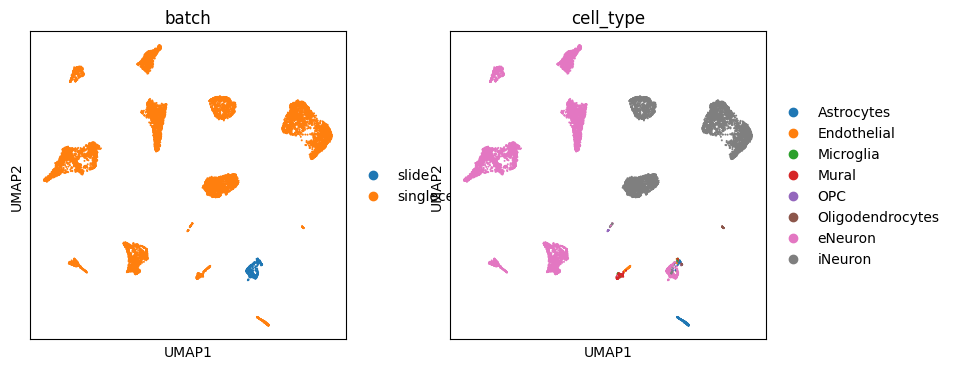

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-PCIE-40GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 400/400: 100%|██████████| 400/400 [04:19<00:00,  1.59it/s, v_num=1, train_loss_step=507, train_loss_epoch=505]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [04:19<00:00,  1.54it/s, v_num=1, train_loss_step=507, train_loss_epoch=505]


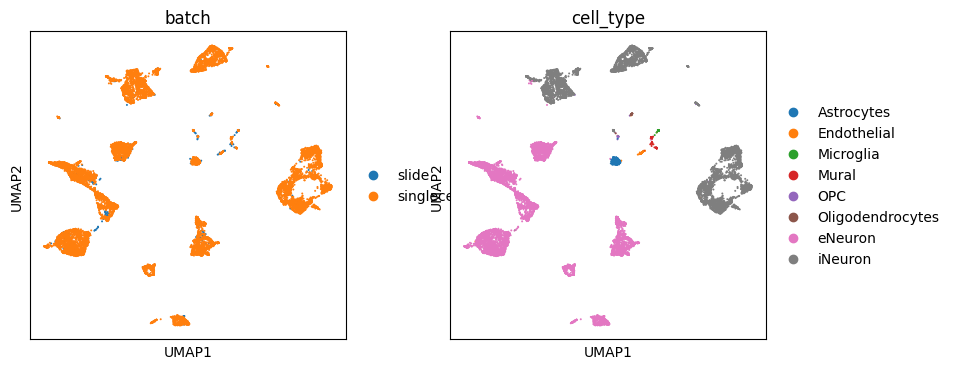

INFO     Training for 20 epochs.                                                                                   


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 20/20: 100%|██████████| 20/20 [00:33<00:00,  1.62s/it, v_num=1, train_loss_step=477, train_loss_epoch=481]

`Trainer.fit` stopped: `max_epochs=20` reached.


Epoch 20/20: 100%|██████████| 20/20 [00:33<00:00,  1.67s/it, v_num=1, train_loss_step=477, train_loss_epoch=481]


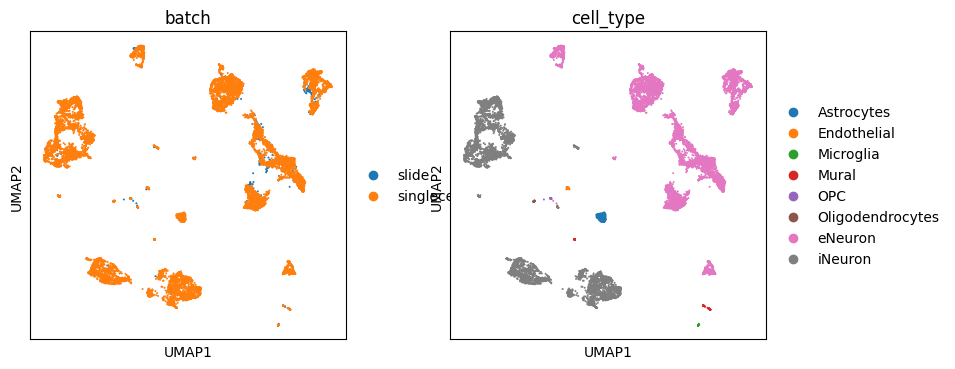

In [3]:
plt.rcParams["figure.figsize"] = (4, 4)
#remove batch effect
adata_sc, adata_sp = cb.utils.run_scvi(slide, singlecell, run_hvg=False)

We reconstruct genes expression matrices of the two datasets using `Seurat` to ensure that the feature dimensions are comparable. The reconstructed gene expression matrices are stored in `csv` format in the `dictory_matrix` directory.

In [4]:
#reconstruct expression matrices of HVGs
dictory_sc = "../CellBack/test/sc/"
dictory_st = "../CellBack/test/st/"
dictory_matrix = "../CellBack/test/"
adata_sc_re, adata_sp_re = cb.utils.run_seurat(adata_sp, adata_sc, dictory_sc = dictory_sc, dictory_st = dictory_st, dictory_matrix = dictory_matrix)


    an issue that caused a segfault when used with rpy2:
    https://github.com/rstudio/reticulate/pull/1188
    Make sure that you use a version of that package that includes
    the fix.
    

R[write to console]: Want to understand how all the pieces fit together? Read R for Data
Science: https://r4ds.hadley.nz/



[1] 4 4 0



R[write to console]: Centering and scaling data matrix

  |                                                                            
  |                                                                      |   0%
  |                                                                            
  |======================================================================| 100%
R[write to console]: 

R[write to console]: PC_ 1 
Positive:  Sars, Nap1l5, Gng3, Zcchc12, Gad2, Rpp25, Cnr1, Dner, Mblac2, Slc6a1 
	   Snx16, Cops4, Erbb4, Nars, Sdhaf2, Zmym2, Nrip3, Nxph1, Kit, Grpel2 
	   Htr3a, Pank2, Kcnc2, Galnt14, Epdr1, Reep5, Tmeff2, Rcan2, Nap1l2, Nrip2 
Negative:  Epn1, Dlgap3, Prrc2a, Clip2, Gpr162, Lmtk3, Lrrc4b, Kcnj4, Fam57b, Ppp1r9b 
	   Grik5, Map3k10, Scaf1, Prrc2b, Zmiz2, Synpo, Agpat1, Maz, Pcdh1, Slc25a23 
	   Kif3c, Klc2, Sptbn4, Fscn1, Tmem151b, Cadm3, Inpp4a, Them6, Hnrnpl, Fam171a2 
PC_ 2 
Positive:  Slc6a1, Gad2, Rpp25, Dner, Erbb4, Zcchc12, Abat, Dlx1, Nxph1, Maf 
	   Btbd

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 14772
Number of edges: 606821

Running Louvain algorithm...


...

R[write to console]: Warning:
R[write to console]:  Layer counts isn't present in the assay object; returning NULL

R[write to console]: Centering and scaling data matrix

  |                                                                            
  |                                                                      |   0%
  |                                                                            
  |======================================================================| 100%
R[write to console]: 

R[write to console]: PC_ 1 
Positive:  Ntsr2, Mfsd2a, Ttyh2, Col4a2, Ltbp4, Lfng, Epas1, Nid1, Fn1, Sorbs3 
	   Myh9, Eng, Afap1l1, Gjb6, Fam107a, Ptprz1, Gpr37l1, Csrp1, Itgb5, Grin2c 
	   Sox9, Sox8, Slc9a3r1, Slc7a10, S1pr1, Slc29a3, Bcam, Acsbg1, Cspg4, Fgfr3 
Negative:  Pacsin1, Rusc1, Them6, Fam57b, Gpr162, Sult4a1, Dmtn, Slc45a1, Mypop, Svop 
	   Mast1, Ak1, Sptbn4, Megf8, Arhgap39, Prepl, Mapk8ip2, Chd5, Rap1gap, Cadm3 
	   Fhod3, Tmem151b, Ptprn2, Lmtk3, Klc2, Gabbr2, Cli

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 14772
Number of edges: 554981

Running Louvain algorithm...


R[write to console]: 0%   10   20   30   40   50   60   70   80   90   100%

R[write to console]: [----|----|----|----|----|----|----|----|----|----|

R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: 

Maximum modularity in 10 random starts: 0.9524
Number of communities: 20
Elapsed time: 1 seconds


R[write to console]: 15:25:31 UMAP embedding parameters a = 0.9922 b = 1.112

R[write to console]: 15:25:31 Read 14772 rows and found 50 numeric columns

R[write to console]: 15:25:31 Using Annoy for neighbor search, n_neighbors = 30

R[write to console]: 15:25:31 Building Annoy index with metric = cosine, n_trees = 50

R[write to console]: 0%   10   20   30   40   50   60   70   80   90   100%

R[write to console]: [----|----|----|----|----|----|----|----|----|----|

R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: 

## 4. Construct graphs and extract features

We use `BANKSY` to obtain the microenvironment representations for ST data. lambda_list = [0.9] indicates that the weights of intrinsic expression versus microenvironment expression are 0.9 and 0.1, respectively. The microenvironment representations for ST data can be found in `adata_sp_micro.X`. Edges among spatial cells are determined using parameter threshold_distance, if and only if the Euclidean distance between two spatial cells is less then threshold_distance, then they are connected. We show the mean degree of spatial cells for users to adjust this paremeter. Connections between spatial cells and single cells are established based on similarity in the low-dimensional embeddings obtained from `scANVI` which are stored in `adata_sc.obsm['X_scANVI']` and `adata_sp.obsm['X_scANVI']`, where parameter k specifies the number of most similar single cells linked to each spatial cell. We use the `cb.utils.extra_features` function to extract features as inputs for the subsequent graph attention network.

In [5]:
#run BANKSY
lambda_list = [0.9]
adata_sp_micro, micro_weight = cb.utils.run_banksy(adata_sp_re, lambda_list=lambda_list)

edge_index_intra = cb.utils.intra_spatial_proximity(adata_sp_re,
                                                          threshold_distance=240)
edge_index_inter = cb.utils.inter_correlation_calculation(adata_sc_re,
                                                                adata_sp_re, basis='X_scANVI', k=3)
edge_index = edge_index_intra + edge_index_inter

lam = micro_weight
features, targets = cb.utils.extra_features(adata_sc_re,
                                            adata_sp_re,
                                            adata_sp_micro, lam=lam)


Median distance to closest cell = 102.6533569835882

---- Ran median_dist_to_nearest_neighbour in 0.01 s ----


Median distance to closest cell = 102.6534

---- Ran generate_spatial_distance_graph in 0.00 s ----

---- Ran row_normalize in 0.00 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.02 s ----

---- Ran generate_spatial_distance_graph in 0.00 s ----

---- Ran theta_from_spatial_graph in 0.01 s ----

---- Ran row_normalize in 0.00 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.02 s ----

Runtime Jan-16-2026-15-26

900 genes to be analysed:
Gene List:
Index(['Usp40', 'Pank2', 'Nrip2', 'Tmem245', 'Col6a1', 'Slc7a4', 'Adam19',
       'Abcf1', 'Pip4k2c', 'Gm1966',
       ...
       'Ptprn2', 'Gng7', 'Them6', 'Diras2', 'Nsmf', 'Eng', 'Fscn1', 'Ppp1r9b',
       'Gpr37l1', 'Ina'],
      dtype='object', length=900)

Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <523x523 sparse matrix of type '<class 'numpy.float64'>'
	with 7845 stored elements in Compr

100%|██████████| 523/523 [00:02<00:00, 246.56it/s]


Mean degree(neighbors): 3.7466539196940727


100%|██████████| 14249/14249 [06:31<00:00, 36.44it/s]


## 5. Microenvironment representations learning for scRNA-seq data

Then, we obtain microenvironment representations for scRNA-seq data through a multi-head graph attention network, which adaptively propagates microenvironmental information from ST data, thereby transferring spatial contexts from spatial omics to single-cell data, using the `cb.micro_network_training` function.

In [6]:
#microenvironment representations learning
celltype_list = adata_sc_re.obs['cell_type'].unique()
cb.micro_network_training(adata_sc=adata_sc_re,
                          adata_sp=adata_sp_re,
                          edge_index=edge_index,
                          features=features,
                          targets=targets,
                          cell_types=celltype_list,
                          epoch=30000,
                          hidden_dim=100,
                          heads=9,
                          )

Epoch 0, Loss: 4.2853
Epoch 1000, Loss: 1.0019
Epoch 2000, Loss: 0.7357
Epoch 3000, Loss: 0.6063
Epoch 4000, Loss: 0.5362
Epoch 5000, Loss: 0.4865
Epoch 6000, Loss: 0.4521
Epoch 7000, Loss: 0.4292
Epoch 8000, Loss: 0.4060
Epoch 9000, Loss: 0.3812
Epoch 10000, Loss: 0.3712
Epoch 11000, Loss: 0.3555
Epoch 12000, Loss: 0.3472
Epoch 13000, Loss: 0.3327
Epoch 14000, Loss: 0.3277
Epoch 15000, Loss: 0.3200
Epoch 16000, Loss: 0.3129
Epoch 17000, Loss: 0.3076
Epoch 18000, Loss: 0.3031
Epoch 19000, Loss: 0.2970
Epoch 20000, Loss: 0.2908
Epoch 21000, Loss: 0.2863
Epoch 22000, Loss: 0.2844
Epoch 23000, Loss: 0.2815
Epoch 24000, Loss: 0.2768
Epoch 25000, Loss: 0.2739
Epoch 26000, Loss: 0.2761
Epoch 27000, Loss: 0.2721
Epoch 28000, Loss: 0.2685
Epoch 29000, Loss: 0.2684


## 6. Gene imputation (using "micro-aware" mode)

We modify the `Tangram` framework by incorporating microenvironmental information, selecting the top k single cells that are similar in both intrinsic and microenvironment gene expression to each spatial cell for gene imputation. Specifically, we obtain the predicted gene expression profiles using the `cb.gene_imputation` function, setting the parameter mode='micro'. Of course, we also allow users to perform gene imputation using all single cells, similar to `Tangram`, by setting the parameter mode='no_micro'.

In [7]:
#gene imputation -> micro-aware
slide = sc.read_h5ad(data_dir / "dataset4_st.h5ad")
singlecell = sc.read_h5ad(data_dir / "dataset4_sc.h5ad")

expression_predicted = cb.gene_imputation(
    mode="micro",
    adata_sp=adata_sp_re,
    adata_sc=adata_sc_re,
    slide=slide,
    singlecell=singlecell,
    train_list=inter_gene,
    k=6000,
    num=30000,
    device="auto",
)

100%|██████████| 14249/14249 [07:01<00:00, 33.78it/s]


Epoch 0, Loss: -0.6848
Epoch 1000, Loss: -0.8828
Epoch 2000, Loss: -0.8830
Epoch 3000, Loss: -0.8831
Epoch 4000, Loss: -0.8831
Epoch 5000, Loss: -0.8832
Epoch 6000, Loss: -0.8832
Epoch 7000, Loss: -0.8832
Epoch 8000, Loss: -0.8832
Epoch 9000, Loss: -0.8832
Epoch 10000, Loss: -0.8832
Epoch 11000, Loss: -0.8832
Epoch 12000, Loss: -0.8832
Epoch 13000, Loss: -0.8832
Epoch 14000, Loss: -0.8832
Epoch 15000, Loss: -0.8832
Epoch 16000, Loss: -0.8832
Epoch 17000, Loss: -0.8832
Epoch 18000, Loss: -0.8832
Epoch 19000, Loss: -0.8832
Epoch 20000, Loss: -0.8832
Epoch 21000, Loss: -0.8832
Epoch 22000, Loss: -0.8832
Epoch 23000, Loss: -0.8832
Epoch 24000, Loss: -0.8832
Epoch 25000, Loss: -0.8832
Epoch 26000, Loss: -0.8832
Epoch 27000, Loss: -0.8832
Epoch 28000, Loss: -0.8832
Epoch 29000, Loss: -0.8832


## 7. Caculate mean PCC of test genes

We calculate the average Pearson correlation coefficient (PCC) for the 10th-fold test genes. `CellBack` exhibits a significant improvement compared to `Tangram`.

In [8]:
#caculate PCC
test_gene_indices = [singlecell.var_names.get_loc(gene) for gene in test_genes]
predict_expression = expression_predicted[:, test_gene_indices]

test_genes_idx = [slide.var_names.get_loc(gene) for gene in test_genes]
true_expression = slide.X[:, test_genes_idx]

import scipy.stats as st
correlation_list = []
for j in range(predict_expression.shape[1]):
    predict_expression[:, j] = np.nan_to_num(predict_expression[:, j], nan=1e-20)
    true_expression[:, j] = np.nan_to_num(true_expression[:, j], nan=1e-20)
    corr, _ = st.pearsonr(predict_expression[:, j], true_expression[:, j])
    correlation_list.append(corr)

correlation_array = np.array(correlation_list)
mean_correlation = np.mean(correlation_array)
print("mean PCC:", mean_correlation)

mean PCC: 0.7486598330469691


## 8. Marker genes visualization

Igsf21 and Rprm are two genes that are highly expressed in the L5/L6 cortical layers of the mouse brain. We visualize both the predicted and ground-truth spatial distributions of these two genes. `CellBack` achieves higher Pearson correlation coefficients (PCCs) than `Tangram`.

PCC of Igsf21: 0.8375961831723074


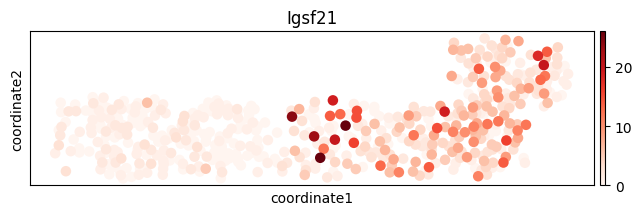

In [23]:
#marker gene visualization
G_predicted = np.array(expression_predicted)
Igsf21_idx = slide.var_names.get_loc("Igsf21")
Igsf21_expression = slide.X[:, Igsf21_idx]
Igsf21_idx = singlecell.var_names.get_loc("Igsf21")
Igsf21_pre = G_predicted[:, Igsf21_idx]
Igsf21_expression = np.nan_to_num(Igsf21_expression, nan=1e-20)
Igsf21_pre = np.nan_to_num(Igsf21_pre, nan=1e-20)
corr, _ = st.pearsonr(Igsf21_expression, Igsf21_pre)
print("PCC of Igsf21:", corr)

plt.rcParams["figure.figsize"] = (8, 2)
#raw_Igsf21
fig = sc.pl.embedding(slide, basis="coordinate", color="Igsf21", cmap="Reds", return_fig=True)
fig.show()

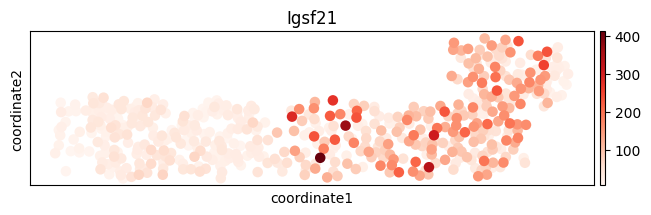

In [24]:
#predict_Igsf21
Igsf21_idx = slide.var_names.get_loc("Igsf21")
slide.X[:, Igsf21_idx] = Igsf21_pre
fig = sc.pl.embedding(slide, basis="coordinate", color="Igsf21", cmap="Reds", return_fig=True)
fig.show()

PCC of Rprm: 0.8059243468521781


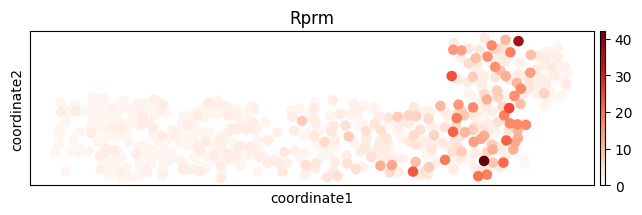

In [25]:
Rprm_idx = slide.var_names.get_loc("Rprm")
Rprm_expression = slide.X[:, Rprm_idx]
Rprm_idx = singlecell.var_names.get_loc("Rprm")
Rprm_pre = G_predicted[:, Rprm_idx]
Rprm_expression = np.nan_to_num(Rprm_expression, nan=1e-20)
Rprm_pre = np.nan_to_num(Rprm_pre, nan=1e-20)
corr, _ = st.pearsonr(Rprm_expression, Rprm_pre)
print("PCC of Rprm:", corr)

#raw_Rprm
fig = sc.pl.embedding(slide, basis="coordinate", color="Rprm", cmap="Reds", return_fig=True)
fig.show()

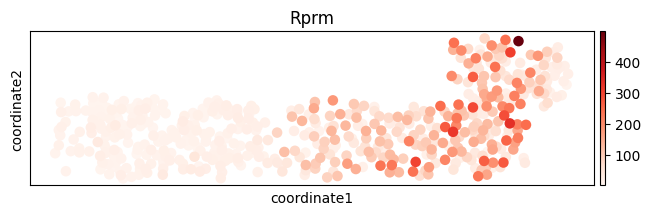

In [26]:
#predict_Rprm
Rprm_idx = slide.var_names.get_loc("Rprm")
slide.X[:, Rprm_idx] = Rprm_pre
fig = sc.pl.embedding(slide, basis="coordinate", color="Rprm", cmap="Reds", return_fig=True)
fig.show()